# **1. ASR(Automatic Speech Recognition) - 자동 음성 인식**
- 자동 음성인식. 사람이 말하는 소리를 컴퓨터가 글자로 바꾸는 기술
- Qwen3-ASR: ASR을 수행하는 AI 모델 다룰거야
- 유명한 모델로는 Whisper: OpenAI에서 개발한 ASR 모델
- 이런걸 STT라 하는데: Speech-to-Text의 약자로, 음성을 텍스트로 변화하는 기능임!

아래 코드 용어를 봐, 예제가 중요한게 아니야

In [1]:
# 소리를 측정한다 = 소리 신호가 얼마나 위쪽 or 아래쪽으로 흔들리는지 숫자로 표현하는거
import numpy as np

# 소리 신호를 배열로 표현
# 마이너스는 나쁜 소리가 아니라 파형의 반대 방향인거다~
data = np.array([0.0, 0.4, 0.8, 0.4, 0.0, -0.4, -0.8, -0.4, 0.0], dtype=np.float32)

print("측정값:", data)
print("측정 횟수:", len(data))
print("가장 큰 절댓값:", np.max(np.abs(data)))

측정값: [ 0.   0.4  0.8  0.4  0.  -0.4 -0.8 -0.4  0. ]
측정 횟수: 9
가장 큰 절댓값: 0.8


이것도 식보다 개념 알기!! 알았냐

### **1-1. Hz(헤르츠)**
- Hz(헤르츠): 1초 동안 소리 신호가 몇 번 진동하는지 나타내는 단위
    - 440Hz = 1초에 440번 진동하는 소리임
- 샘플링 레이트(sampling rate): 1초에 소리 신호를 몇 번 측정하는지 나타내는 단위
    - 1 KHz = 1000 Hz
    - 16 KHz = 16000 Hz

> 소리의 주파수(음 높이 관련) Hz와 샘플링 레이트(측정 횟수 관련) Hz는 다르다!!
- 주파수 = 소리가 1초에 얼마나 진동하는지?
- 샘플링 레이트 = 컴퓨터가 1초에 소리 신호를 몇 번 측정하는지?

![주파수와 샘플링 레이트 차이](./images/ref/04_01.png)

In [2]:
sample_rate = 16000  # 1초에 16000번 측정한다는 의미
seconds = 4 # 측정할 시간(초)
num_samples = sample_rate * seconds  # 총 측정 횟수

print(f"{seconds}초 동안 만들어지는 측정값: {num_samples:,}개")

4초 동안 만들어지는 측정값: 64,000개


In [3]:
import numpy as np
import matplotlib.pyplot as plt

In [4]:
# 맷플로립 한글폰트 깨지는거 수정
plt.rcParams['font.family'] = 'Malgun Gothic'

d:\OSA\14_Agent\qwen_asr_test\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


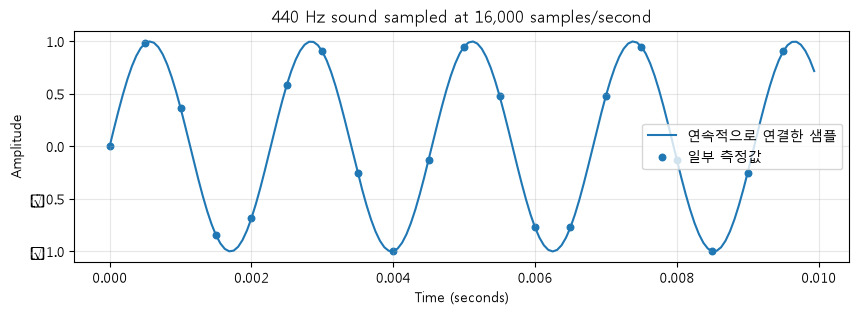

In [5]:
sample_rate = 16000
duration = 0.01
t = np.arange(int(sample_rate * duration)) / sample_rate
frequency = 440
wave = np.sin(2 * np.pi * frequency * t)
plt.figure(figsize=(10, 3))
plt.plot(t, wave, label='연속적으로 연결한 샘플')
plt.scatter(t[::8], wave[::8], s=22, label='일부 측정값')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.title('440 Hz sound sampled at 16,000 samples/second')
plt.legend()
plt.grid(alpha=.3)
plt.show()

### **1-2. WAV 파일**
- 확장자 WAV는 디지털 소리를 담는 파일 형식임
- 압축되지 않은 PCM(Pulse Code Modulation) 방식으로 소리 데이터를 저장할 수 있음
    - MP3는요? -> 이건 엄청 압축된 파일임
- 모노(Mono): 소리 채널이 하나인 경우 **→ channel 1**
- 스테레오(Stereo): 소리 채널이 두 개인 경우 **→ channel 2**
    - 왼쪽 채널과 오른쪽 채널로 나뉘어 소리가 재생됨
- float32로 소리 측정값 저장함. 32비트 부동소수점 형태임!

```
예를 들어 16KHz 모노 4초라면
튜플 (64000,)모양의 1차원 배열로 표현이 가능하고
녹음 라이브러리 (64000, 1)처럼 채널 축을 포함해서 사용함
> 스테레오라면 (64000, 2) 모양의 2차원 배열로 표현됨

왜 64000이냐면 16KHz * 4초 = 64000이기 때문임!
```


In [6]:
# pip install soundfile

# soundfile의 역할
# 파이썬에서 사용하는건데~
# 음성 파일을 읽거나 저장할 때 사용하는 모듈임
# 에를 들어 WAV같은 소리 파일을 숫자 데이터로 가져오거나 or 숫자 데이터를 다시 소리파일로 저장하는 도구임!
import soundfile as sf

In [7]:
# 샘플링 레이트 설정 = 1초에 소리를 16000번 측정
sr = 16000

t = np.arange(sr) / sr # 1초 동안의 시간 축 생성

# 440Hz 사인파 생성 
# 440: 1초에 440번 진동하는 소리 (440Hz)
# 0.2: 만들어진 소리신호의 크기를 조절하는 값 (진폭)
# 쉽게 말해 440Hz 소리를 1초 동안 WAV 파일로 만들어서 저장!
tone = (0.2 * np.sin(2 * np.pi * 440 * t)).astype(np.float32)  

# 사운드 파일로 저장
sf.write('practice_440Hz.wav', tone, sr) 

# 사운드 파일 읽기
loaded, loaded_sr = sf.read('practice_440Hz.wav') 

print("저장된 샘플링 레이트:", loaded_sr)
print("샘플 개수:", len(loaded))
print("녹음 길이:", len(loaded) / loaded_sr, "초")

저장된 샘플링 레이트: 16000
샘플 개수: 16000
녹음 길이: 1.0 초


### **1-3. Qwen3-ASR**
- Qwen 팀이 공개한 자동 음성인식 모델
- Qwen3-ASR-1.7B 사용할건데
    - Qwen3-ASR: 음성인식이 목적인 모델
    - 1.7B: 약 17억 개의 매개변수(파라미터)를 가진 모델 >> B = Billion (10억)

> pip install qwen-asr

In [8]:
from qwen_asr import Qwen3ASRModel

d:\OSA\14_Agent\qwen_asr_test\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [9]:
import random
import torch

In [10]:
SEED = 2026

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cpu


In [14]:
model_name = "Qwen/Qwen3-ASR-1.7B"

# bfloat16: 메모리 절약. FP32와 비슷한 지수 범위
# FP16: 메모리 절약. 지수 범위는 FP32보다 좁음
dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16

# max_inference_batch_size: 한 번에 추론 배치에서 처리할 최대 음성 입력 개수
# 예) batch size가 1이면 음성1, 음성2, 음성3등등 각각 음성들이 나누어져있을 때 하나씩 순차적으로 배치처리 할게!
# batch size가 3이면 음성1, 음성2, 음성3을 한 번에 배치처리 할게!
# 그럼 batch size가 2면? 음성1, 음성2를 한 번에 배치처리 하고 음성 3은 그 다음에 배치처리 할게!

# max_new_tokens: 모델이 새롭게 생성할 수 있는 토큰의 최대 개수
# 예) max_new_tokens가 256이면 모델이 한 번에 최대 256개의 토큰을 생성할 수 있어.
# 토큰은 한 글자, 한 단어 아니고 모델마다 처리하는 개념이 다 다르니 참고하기~!
# 예) '오늘은 인공지능을 공부합니다'라는 문자열이 있다면 
# 토크나이저는 문장을 모델에서 사용하는 토큰으로 나누어줄건데
# 최대 256개의 출력 토큰을 만드는건데(무조건 256개를 만든다는 뜻은 아님)
# 그럼 5초동안 얘기하면 256개 다 못채울텐데 모자라면 padding으로 채울거고 넘치면 잘라내는..?!
model = Qwen3ASRModel.from_pretrained(
    model_name, max_inference_batch_size=1, device_map=DEVICE, max_new_tokens=256, dtype=dtype
)

Loading checkpoint shards: 100%|██████████| 2/2 [00:11<00:00,  5.92s/it]


In [15]:
from pathlib import Path

In [ ]:
if Path('sample.wav').exists():

    # SoundFile이란? 오디오 파일을 읽고 쓸 수 있는 라이브러리
    # 숫자 데이터로 가져오는~!
    with sf.SoundFile('sample.wav') as f:
        # samplerate: 1초동안 음성신호를 몇 번 측정했는지(샘플링했는지)
        # 단위는 Hz(헤르츠)
        sr = f.samplerate
        # sr * 5: 5초 동안의 오디오 샘플 수
        audio = f.read(frames=sr * 5, dtype='float32')

    # if audio.ndim == 2: 스테레오 오디오일 경우
    # ndim: 넘파이 배열의 차원 수
    if audio.ndim == 2:
        # 두 채널을 평균내어 모노로 변환
        audio = audio.mean(axis=1)
    """
        audio = np.array([0.1, 0.3, -0.2, 0.4])
        print(audio.ndim) # 1
        audio = np.array([
            [0.1, 0.3],
            [-0.2, 0.4],
            [-0.3, 0.5]
        ])
        print(audio.ndim) # 2
        audio.mean(axis=1) # 
    """

    print('샘플링 레이트:', sr)
    print('음성 길이:', len(audio) / sr, '초')

    # transcribe(): 모델에 음성을 입력하여 텍스트로 변환
    results = model.transcribe(
        audio=(audio, sr),
        language='Korean'
    )

    print('인식 결과:', results[0].text)

else:
    print('sample.wav를 준비한 후 다시 실행하세요.')

샘플링 레이트: 16000
음성 길이: 5.0 초


Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


인식 결과: 국내 의료계가 또다시 숙련이고 있습니다. WTO를 중심으로 한


위에것들을 이제 챕터4와 연결해서 음성 인식 실습을..!?

ㅁ